# Pill defect classifier (ResNet-50, transfer learning)

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import roc_auc_score, average_precision_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")

Device: cuda NVIDIA GeForce RTX 5070 Ti


In [2]:
IMG_SIZE = 256
DATA_DIR = "./data/NEU_Defect_Dataset/pill"

raw = datasets.ImageFolder(DATA_DIR, transform=transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.PILToTensor()]))
assert len(raw.classes) >= 2, f"Need at least 2 class folders, found {raw.classes}"

loader = DataLoader(raw, batch_size=64, num_workers=4)   # no shuffle -> order matches raw.targets
X = torch.cat([x for x, _ in loader]).to(device)         # uint8, [N, 3, H, W]
Y = torch.cat([y for _, y in loader]).to(device)         # int64, [N]
C = len(raw.classes)
bad_i = raw.classes.index("bad")

mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def prep(xb, augment):
    x = xb.float() / 255
    if augment:   
        n = x.size(0)
        x = torch.where((torch.rand(n, device=device) < 0.5)[:, None, None, None], x.flip(3), x)
        x = torch.where((torch.rand(n, device=device) < 0.5)[:, None, None, None], x.flip(2), x)
    return (x - mean) / std

g = torch.Generator().manual_seed(42)
train_parts, val_parts = [], []
for c in range(C):
    idx_c = (Y == c).nonzero(as_tuple=True)[0].cpu()
    idx_c = idx_c[torch.randperm(len(idx_c), generator=g)]
    n_train = int(0.8 * len(idx_c))
    train_parts.append(idx_c[:n_train])
    val_parts.append(idx_c[n_train:])
train_idx = torch.cat(train_parts).to(device)
val_idx = torch.cat(val_parts).to(device)

counts = torch.bincount(Y[train_idx], minlength=C).float()
class_weights = counts.sum() / (C * counts)

print("Classes:", raw.classes)
print("Train:", len(train_idx), "| Val:", len(val_idx))
print("Class weights:", class_weights.tolist())

Classes: ['bad', 'good']
Train: 693 | Val: 175
Class weights: [1.5399999618530273, 0.7403846383094788]


In [3]:
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
model.fc = nn.Linear(model.fc.in_features, C)   # 2048 -> C
model = model.to(device)

In [4]:
criterion = nn.CrossEntropyLoss(weight=class_weights)
# Small lr for the pretrained layers, larger lr for the new randomly-initialized layer
new_params = list(model.fc.parameters())
new_ids = {id(p) for p in new_params}
pretrained_params = [p for p in model.parameters() if id(p) not in new_ids]
optimizer = optim.Adam([
    {"params": pretrained_params, "lr": 1e-4},
    {"params": new_params,        "lr": 1e-3},
])

epochs = 15
bs = 32

def evaluate():
    """Returns val loss, val accuracy, per-class recall, class probabilities, labels."""
    model.eval()
    loss, probs = 0.0, []
    with torch.no_grad():
        for i in range(0, len(val_idx), 128):
            idx = val_idx[i:i + 128]
            out = model(prep(X[idx], augment=False))
            loss += F.cross_entropy(out, Y[idx], reduction="sum").item()
            probs.append(out.softmax(1))
    probs = torch.cat(probs)
    labels = Y[val_idx]
    pred = probs.argmax(1)
    acc = (pred == labels).float().mean().item()
    recall = [(pred[labels == c] == c).float().mean().item() for c in range(C)]
    return loss / len(val_idx), acc, recall, probs, labels

In [5]:
for epoch in range(epochs):
    model.train()
    perm = train_idx[torch.randperm(len(train_idx), device=device)]
    train_loss = 0.0
    for i in range(0, len(perm), bs):
        idx = perm[i:i + bs]
        loss = criterion(model(prep(X[idx], augment=True)), Y[idx])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * len(idx)

    val_loss, val_acc, recall, _, _ = evaluate()
    recall_str = ", ".join(f"{n} {r*100:.1f}%" for n, r in zip(raw.classes, recall))
    print(f"Epoch {epoch+1:02d}/{epochs} | train loss {train_loss/len(perm):.4f} | "
          f"val loss {val_loss:.4f} | val acc {val_acc*100:.2f}% | recall: {recall_str}")

Epoch 01/15 | train loss 0.4362 | val loss 0.3850 | val acc 82.86% | recall: bad 47.4%, good 100.0%
Epoch 02/15 | train loss 0.3078 | val loss 0.2631 | val acc 88.57% | recall: bad 64.9%, good 100.0%
Epoch 03/15 | train loss 0.2286 | val loss 0.8176 | val acc 53.14% | recall: bad 80.7%, good 39.8%
Epoch 04/15 | train loss 0.1621 | val loss 0.9507 | val acc 55.43% | recall: bad 82.5%, good 42.4%
Epoch 05/15 | train loss 0.1578 | val loss 0.1394 | val acc 94.86% | recall: bad 96.5%, good 94.1%
Epoch 06/15 | train loss 0.1020 | val loss 0.7252 | val acc 84.57% | recall: bad 52.6%, good 100.0%
Epoch 07/15 | train loss 0.0723 | val loss 0.1744 | val acc 93.71% | recall: bad 82.5%, good 99.2%
Epoch 08/15 | train loss 0.0288 | val loss 0.1169 | val acc 96.57% | recall: bad 94.7%, good 97.5%
Epoch 09/15 | train loss 0.0607 | val loss 0.0957 | val acc 97.14% | recall: bad 93.0%, good 99.2%
Epoch 10/15 | train loss 0.0423 | val loss 0.1069 | val acc 97.14% | recall: bad 91.2%, good 100.0%
Epoch 

In [6]:
_, _, _, probs, labels = evaluate()
p_bad = probs[:, bad_i].cpu().numpy()
is_bad = (labels == bad_i).cpu().numpy()

print(f"ROC AUC: {roc_auc_score(is_bad, p_bad):.3f}")
print(f"Average precision (bad): {average_precision_score(is_bad, p_bad):.3f}")

THRESHOLD = 0.5  

pred_bad = p_bad >= THRESHOLD
acc      = (pred_bad == is_bad).mean()
rec_bad  = (pred_bad & is_bad).sum() / is_bad.sum()
rec_good = (~pred_bad & ~is_bad).sum() / (~is_bad).sum()
print(f"\nThreshold {THRESHOLD}: acc {acc*100:.2f}% | bad recall {rec_bad*100:.1f}% | good recall {rec_good*100:.1f}%")

print("\nThreshold sweep:")
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    pb = p_bad >= t
    print(f"t={t:.1f} | bad recall {(pb & is_bad).sum() / is_bad.sum() * 100:.1f}% "
          f"| good recall {(~pb & ~is_bad).sum() / (~is_bad).sum() * 100:.1f}%")

ROC AUC: 0.995
Average precision (bad): 0.993

Threshold 0.5: acc 98.29% | bad recall 98.2% | good recall 98.3%

Threshold sweep:
t=0.5 | bad recall 98.2% | good recall 98.3%
t=0.4 | bad recall 98.2% | good recall 97.5%
t=0.3 | bad recall 98.2% | good recall 96.6%
t=0.2 | bad recall 98.2% | good recall 95.8%
t=0.1 | bad recall 98.2% | good recall 90.7%


## Results

Charts of the run above. Metrics are copied from the printed logs; the confusion matrix counts are derived from the logged recalls and the validation class sizes (57 bad, 118 good).

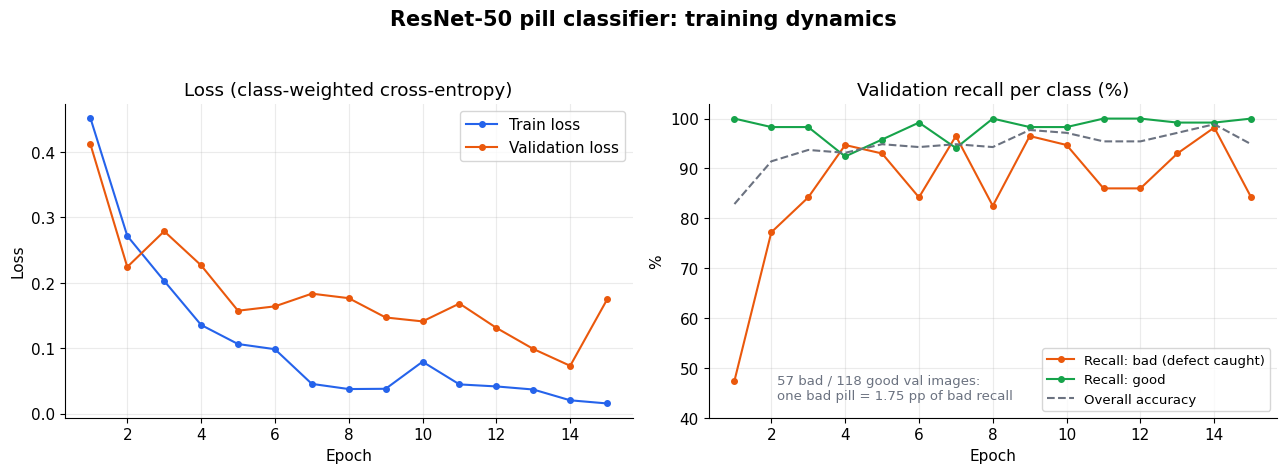

In [7]:
# ---- Results 1: training dynamics (values copied from the training log above) ----
import matplotlib.pyplot as plt

BLUE, ORANGE, GREEN, GRAY = "#2563eb", "#ea580c", "#16a34a", "#6b7280"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})

train_loss = [0.4518, 0.2715, 0.2027, 0.1354, 0.1062, 0.0983, 0.0453, 0.0374, 0.0378, 0.0792, 0.0445, 0.0414, 0.0367, 0.0202, 0.0154]
val_loss   = [0.4118, 0.2240, 0.2786, 0.2265, 0.1571, 0.1638, 0.1832, 0.1763, 0.1468, 0.1408, 0.1681, 0.1309, 0.0987, 0.0729, 0.1743]
val_acc    = [82.86, 91.43, 93.71, 93.14, 94.86, 94.29, 94.86, 94.29, 97.71, 97.14, 95.43, 95.43, 97.14, 98.86, 94.86]
bad_recall = [47.4, 77.2, 84.2, 94.7, 93.0, 84.2, 96.5, 82.5, 96.5, 94.7, 86.0, 86.0, 93.0, 98.2, 84.2]
good_recall= [100.0, 98.3, 98.3, 92.4, 95.8, 99.2, 94.1, 100.0, 98.3, 98.3, 100.0, 100.0, 99.2, 99.2, 100.0]
ep = list(range(1, len(val_acc) + 1))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
fig.suptitle("ResNet-50 pill classifier: training dynamics", fontsize=15, fontweight="bold")

a = ax[0]
a.plot(ep, train_loss, "-o", color=BLUE, ms=4, label="Train loss")
a.plot(ep, val_loss, "-o", color=ORANGE, ms=4, label="Validation loss")
a.set_title("Loss (class-weighted cross-entropy)"); a.set_xlabel("Epoch"); a.set_ylabel("Loss"); a.legend()

a = ax[1]
a.plot(ep, bad_recall, "-o", color=ORANGE, ms=4, label="Recall: bad (defect caught)")
a.plot(ep, good_recall, "-o", color=GREEN, ms=4, label="Recall: good")
a.plot(ep, val_acc, "--", color=GRAY, label="Overall accuracy")
a.set_title("Validation recall per class (%)"); a.set_xlabel("Epoch"); a.set_ylabel("%")
a.set_ylim(40, 103); a.legend(loc="lower right", fontsize=9.5)
a.text(0.12, 0.06, "57 bad / 118 good val images:\none bad pill = 1.75 pp of bad recall",
       transform=a.transAxes, fontsize=9.5, color=GRAY)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


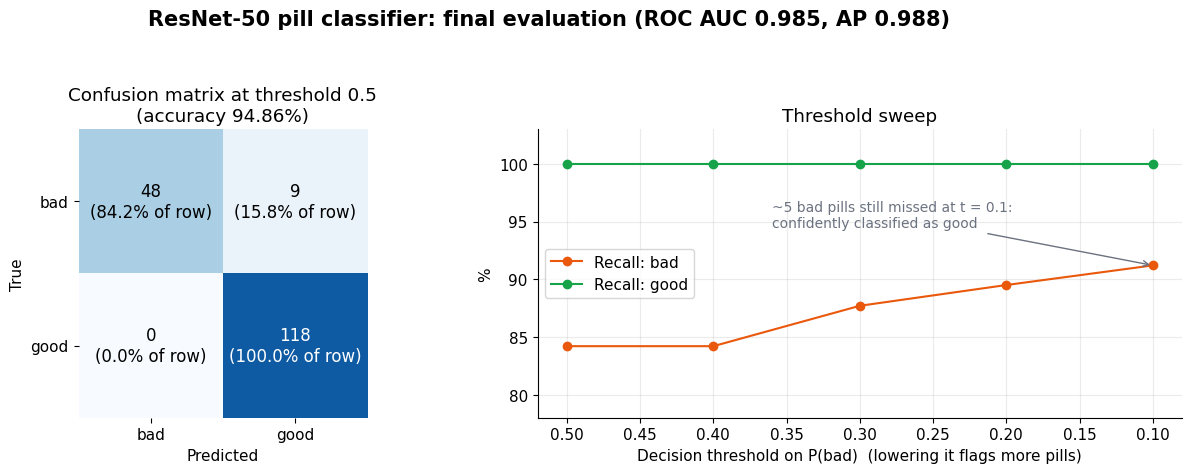

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

ORANGE, GREEN, GRAY = "#ea580c", "#16a34a", "#6b7280"

cm = np.array([[48, 9],     
               [0, 118]])   

thresholds = [0.5, 0.4, 0.3, 0.2, 0.1]
sweep_bad  = [84.2, 84.2, 87.7, 89.5, 91.2]
sweep_good = [100.0, 100.0, 100.0, 100.0, 100.0]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.25]})
fig.suptitle("ResNet-50 pill classifier: final evaluation (ROC AUC 0.985, AP 0.988)", fontsize=15, fontweight="bold")

a = ax[0]
a.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max() * 1.2)
labels = ["bad", "good"]
a.set_xticks([0, 1]); a.set_xticklabels(labels); a.set_yticks([0, 1]); a.set_yticklabels(labels)
a.set_xlabel("Predicted"); a.set_ylabel("True"); a.grid(False)
for i in range(2):
    for j in range(2):
        a.text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum() * 100:.1f}% of row)", ha="center", va="center",
               fontsize=12, color="white" if cm[i, j] > cm.max() * 0.6 else "black")
a.set_title("Confusion matrix at threshold 0.5\n(accuracy 94.86%)")
for s in a.spines.values(): s.set_visible(False)

a = ax[1]
a.plot(thresholds, sweep_bad, "-o", color=ORANGE, label="Recall: bad")
a.plot(thresholds, sweep_good, "-o", color=GREEN, label="Recall: good")
a.invert_xaxis()
a.set_xlabel("Decision threshold on P(bad)  (lowering it flags more pills)")
a.set_ylabel("%"); a.set_ylim(78, 103); a.legend(loc="center left")
a.set_title("Threshold sweep")
a.annotate("~5 bad pills still missed at t = 0.1:\nconfidently classified as good", (0.1, 91.2),
           xytext=(0.36, 94.5), arrowprops=dict(arrowstyle="->", color=GRAY), color=GRAY, fontsize=10)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()
